# Fine-tuning the encoder as a defense, on four encoders

Notebook 07 defended SmolVLM-256M by fine-tuning its vision encoder. It concluded that a defense that blocks the *fixed* perturbation can fail against an attacker who recomputes v against the defended model, and that robustness measured inside the encoder overstates robustness in the answers. Here, the same two defenses on each mini-VLM of notebook 08:
- **FT-fixed**: fine-tune the encoder on images carrying the fixed universal v;
- **FT-UAT**: universal adversarial training, v updated during fine-tuning;
- both: 3 epochs on the 500 build images, with an anchoring term that keeps the clean features close to the original ones; connector and language model unchanged.

Each defended model then faces an **adaptive attacker**: a new universal v computed against it, to convergence.

Files: `results/<encoder>/defense_ft.json`, `defense_ft_captions.json`, `defense_mechanism.json`. Commands: `minivlm/run_defense.sh <encoder>`, then `python defense_mechanism.py --encoder <encoder>`. Report: Part IV.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('minivlm'))   # run from smol_exp/, where notebooks 01-07 are
import numpy as np
import matplotlib.pyplot as plt
from nb_utils import *
use_style()
print('result files read from', RESULTS_DIR)

result files read from /home/kemnhou/Bureau/universal/smol_exp/minivlm/results


## 1. Clean cost, fixed v, adaptive v

In [2]:
VARS = ['no-defense', 'FT-fixed', 'FT-UAT']
def ft(e, var, cond, ds='imagenetv2'):
    r = load(e, 'defense_ft.json')['variants'][var][ds][cond]
    return r['changed@0.5']['all'] if ds == 'imagenetv2' else r['changed']
rows = []
for e in ENC:
    for var in VARS:
        rows.append([NAMES[e] if var == 'no-defense' else '', var, pct(ft(e, var, 'clean cost'), False),
                     pct(ft(e, var, 'fixed v')), '**%s**' % pct(ft(e, var, 'adaptive v')),
                     pct(ft(e, var, 'adaptive v', 'coco'), False)])
show_table(['encoder', 'defense', 'clean captions changed by the defense', 'fixed v', 'adaptive v',
            'adaptive v, COCO'], rows, 'ImageNetV2 held-out, captions changed')

**ImageNetV2 held-out, captions changed**

| encoder | defense | clean captions changed by the defense | fixed v | adaptive v | adaptive v, COCO |
|---|---|---|---|---|---|
| SigLIP | no-defense | 0.0 % | 47.4 % (43.1–51.8) | **48.0 % (43.7–52.4)** | 28.7 % |
|  | FT-fixed | 5.8 % | 16.4 % (13.4–19.9) | **70.4 % (66.3–74.2)** | 64.6 % |
|  | FT-UAT | 4.6 % | 14.8 % (12.0–18.2) | **72.6 % (68.5–76.3)** | 67.8 % |
| CLIP | no-defense | 0.0 % | 79.2 % (75.4–82.5) | **78.6 % (74.8–82.0)** | 69.4 % |
|  | FT-fixed | 11.6 % | 17.6 % (14.5–21.2) | **64.4 % (60.1–68.5)** | 53.0 % |
|  | FT-UAT | 11.4 % | 21.2 % (17.8–25.0) | **63.2 % (58.9–67.3)** | 51.6 % |
| I-JEPA | no-defense | 0.0 % | 80.4 % (76.7–83.6) | **80.8 % (77.1–84.0)** | 75.5 % |
|  | FT-fixed | 8.2 % | 12.8 % (10.2–16.0) | **63.6 % (59.3–67.7)** | 57.3 % |
|  | FT-UAT | 7.8 % | 24.8 % (21.2–28.8) | **77.0 % (73.1–80.5)** | 76.2 % |
| MAE | no-defense | 0.0 % | 92.8 % (90.2–94.8) | **93.2 % (90.6–95.1)** | 93.6 % |
|  | FT-fixed | 3.4 % | 15.2 % (12.3–18.6) | **94.8 % (92.5–96.4)** | 96.4 % |
|  | FT-UAT | 4.2 % | 15.4 % (12.5–18.8) | **85.0 % (81.6–87.9)** | 85.1 % |

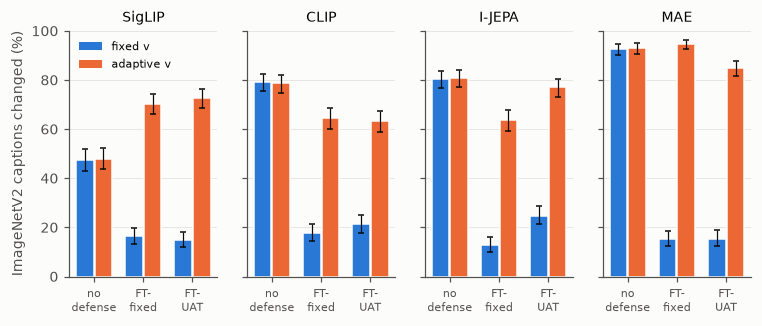

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.9), sharey=True)
for ax, e in zip(axes, ENC):
    xx = np.arange(3)
    bars(ax, xx - 0.19, [ft(e, v, 'fixed v') for v in VARS], BLUE, 'fixed v', 0.36)
    bars(ax, xx + 0.19, [ft(e, v, 'adaptive v') for v in VARS], ORANGE, 'adaptive v', 0.36)
    ax.set_xticks(xx, ['no\ndefense', 'FT-\nfixed', 'FT-\nUAT'], fontsize=7.5)
    ax.set_title(NAMES[e], fontsize=9); ax.set_ylim(0, 100)
axes[0].set_ylabel('ImageNetV2 captions changed (%)'); axes[0].legend(loc='upper left', fontsize=7.5)
plt.show()

The pattern of notebook 07 holds on every encoder. The defense changes 3 to 12 % of clean captions and neutralises the fixed v, but **the adaptive v gets through**: 63 to 95 % of captions still change.

## 2. Against the adaptive attacker, is the defended model better than no defense?

Paired test on the same 500 images: each model's caption under its adaptive v is compared with **its own** clean caption, then McNemar compares the defended model with the undefended one. The caption similarities are recomputed here (MiniLM).

In [4]:
rows = []
for e in ENC:
    c = load(e, 'defense_ft_captions.json')
    flags = {v: changed_flags(c['imagenetv2: %s: clean' % v], c['imagenetv2: %s: adaptive v' % v]) for v in VARS}
    for v in VARS[1:]:
        only_nd, only_def, p = mcnemar(flags['no-defense'], flags[v])
        verdict = 'defense worse' if only_def > only_nd and p < 0.05 else ('defense better' if p < 0.05 else 'no significant difference')
        rows.append([NAMES[e], v, '%.1f %%' % (100 * flags['no-defense'].mean()), '%.1f %%' % (100 * flags[v].mean()),
                     '%d vs %d' % (only_nd, only_def), '%.1g' % p, verdict])
show_table(['encoder', 'defense', 'no defense, adaptive v', 'defended, adaptive v',
            'discordant pairs (only no-def. / only def.)', 'McNemar p', ''], rows)

| encoder | defense | no defense, adaptive v | defended, adaptive v | discordant pairs (only no-def. / only def.) | McNemar p |  |
|---|---|---|---|---|---|---|
| SigLIP | FT-fixed | 48.0 % | 70.4 % | 27 vs 139 | 2e-19 | defense worse |
| SigLIP | FT-UAT | 48.0 % | 72.6 % | 29 vs 152 | 3e-21 | defense worse |
| CLIP | FT-fixed | 78.6 % | 64.4 % | 106 vs 35 | 2e-09 | defense better |
| CLIP | FT-UAT | 78.6 % | 63.2 % | 105 vs 28 | 1e-11 | defense better |
| I-JEPA | FT-fixed | 80.8 % | 63.6 % | 116 vs 30 | 4e-13 | defense better |
| I-JEPA | FT-UAT | 80.8 % | 77.0 % | 59 vs 40 | 0.07 | no significant difference |
| MAE | FT-fixed | 93.2 % | 94.8 % | 14 vs 22 | 0.2 | no significant difference |
| MAE | FT-UAT | 93.2 % | 85.0 % | 57 vs 16 | 2e-06 | defense better |

For CLIP and I-JEPA (FT-fixed), and MAE (FT-UAT), the defense lowers the adaptive attack by 8 to 17 points, but most captions still change. For SigLIP, the most robust encoder without defense, the defended model is **more** vulnerable to its adaptive perturbation than the undefended one (report IV.3, confidence A). A defense must be judged against the attacker who knows it.

## 3. Where it fails: the encoder is protected, the language model's input is not

For each variant, cosine between clean and perturbed features (500 held-out images), at the encoder output (*tokens*) and at the connector output, which is what the language model reads. Damage = 1 − cosine.

SigLIP: FT-fixed and FT-UAT restored from log_defense.txt (3 decimals) after an overwrite by a run on a machine without the defense checkpoints (23 Nov 20:36)
MAE: FT-fixed and FT-UAT restored from log_defense.txt (3 decimals) after an overwrite by a run on a machine without the defense checkpoints (23 Nov 20:36)


| encoder | defense | fixed v: token damage | fixed v: connector damage | adaptive v: token damage | adaptive v: connector damage |
|---|---|---|---|---|---|
| SigLIP | no-defense | 0.75 | 0.34 | 0.75 | 0.34 |
|  | FT-fixed | 0.23 | 0.13 | 0.52 | 0.31 |
|  | FT-UAT | 0.23 | 0.14 | 0.50 | 0.33 |
| CLIP | no-defense | 0.70 | 0.26 | 0.70 | 0.26 |
|  | FT-fixed | 0.18 | 0.07 | 0.43 | 0.17 |
|  | FT-UAT | 0.19 | 0.07 | 0.44 | 0.15 |
| I-JEPA | no-defense | 0.70 | 0.24 | 0.70 | 0.24 |
|  | FT-fixed | 0.15 | 0.05 | 0.49 | 0.20 |
|  | FT-UAT | 0.20 | 0.07 | 0.52 | 0.19 |
| MAE | no-defense | 0.91 | 0.49 | 0.91 | 0.50 |
|  | FT-fixed | 0.03 | 0.02 | 0.43 | 0.38 |
|  | FT-UAT | 0.02 | 0.02 | 0.56 | 0.31 |

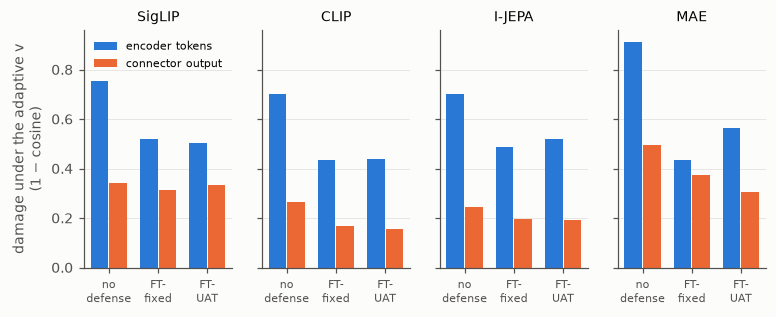

In [5]:
rows = []
for e in ENC:
    d = load(e, 'defense_mechanism.json')
    for v in VARS:
        r = d['variants'][v]
        rows.append([NAMES[e] if v == 'no-defense' else '', v] +
                    ['%.2f' % (1 - r[a][k]) for a in ['fixed v', 'adaptive v'] for k in ['token_cos', 'connector_cos']])
    if 'note' in d:
        print('%s: %s' % (NAMES[e], d['note']))
show_table(['encoder', 'defense', 'fixed v: token damage', 'fixed v: connector damage', 'adaptive v: token damage',
            'adaptive v: connector damage'], rows)

fig, axes = plt.subplots(1, 4, figsize=(8, 2.8), sharey=True)
for ax, e in zip(axes, ENC):
    d = load(e, 'defense_mechanism.json')['variants']
    xx = np.arange(3)
    ax.bar(xx - 0.19, [1 - d[v]['adaptive v']['token_cos'] for v in VARS], 0.36, color=BLUE, label='encoder tokens')
    ax.bar(xx + 0.19, [1 - d[v]['adaptive v']['connector_cos'] for v in VARS], 0.36, color=ORANGE,
           label='connector output')
    ax.set_xticks(xx, ['no\ndefense', 'FT-\nfixed', 'FT-\nUAT'], fontsize=7.5); ax.set_title(NAMES[e], fontsize=9)
axes[0].set_ylabel('damage under the adaptive v\n(1 − cosine)'); axes[0].legend(fontsize=7.5)
plt.show()

Under the adaptive v, the defended encoders' **tokens** are clearly less damaged (SigLIP: 0.75 → about 0.5), but the damage at the **connector output**, which is what the language model reads, barely moves for SigLIP (0.34 → 0.31–0.33) and stays high for MAE. The adaptive attacker finds directions that the defended encoder lets through and that still reach the language model. SigLIP, where this gap is largest, is also where the defense is harmful in the captions. This is the mechanism behind the sentence of notebook 07, "robustness measured inside the encoder overstates robustness in the answers" (report IV.4, confidence B).

## Takeaways

| conf. | finding |
|---|---|
| A | Fine-tuning the encoder: negligible clean cost, effective against the fixed v, ineffective against the adaptive v, on all four encoders. |
| A | For SigLIP the defense is harmful against the adaptive attacker. |
| B | The defense protects the encoder tokens, not what the language model reads. |

**Limits.** One defense family, one training seed per defense, defense tuned and v built on the same 500 images (evaluations on images never used), adaptive attack with a single seed.